# H1 — Does PSNR rise, peak, then fall?

**Hypothesis.** While DIP is fitted to the noisy image, PSNR against the clean image rises, peaks and then falls. The drop after the peak is larger at higher noise.

**Data.** `results/h1/`: U-Net, 4 Kodak images × σ ∈ {25, 50}, seed 0, plus seeds 1–2 on `kodim03`, σ = 25. 10 % of pixels are held out from the loss (needed for H4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io

from dip.analysis import (IMAGES, INK, MODEL_COLORS, MODEL_LABELS, MUTED, PALETTE,
                          load_runs, noisy_baseline, savefig, setup_style, summarize)
from dip.utils import DATA_DIR, RESULTS_DIR, add_gaussian_noise, load_image, to_numpy_image

setup_style()
pd.set_option("display.precision", 2)

In [2]:
h1 = load_runs("h1")
summary = summarize(h1, ["image", "sigma", "seed"])
base = pd.DataFrame([noisy_baseline(im, s) for im in IMAGES for s in (25, 50)])
summary = summary.merge(base, on=["image", "sigma"])
summary["gain_psnr"] = summary["peak_psnr"] - summary["noisy_psnr"]
summary[["image", "sigma", "seed", "noisy_psnr", "peak_psnr", "peak_iter", "final_psnr", "drop_psnr",
         "gain_psnr", "noisy_ssim", "peak_ssim", "peak_iter_ssim", "final_ssim"]]

,image,sigma,seed,noisy_psnr,peak_psnr,peak_iter,final_psnr,drop_psnr,gain_psnr,noisy_ssim,peak_ssim,peak_iter_ssim,final_ssim
0,kodim03,25,0,20.39,28.91,840.0,25.20,3.71,8.52,0.24,0.65,790.0,0.43
1,kodim03,25,1,20.39,28.81,870.0,25.41,3.39,8.42,0.24,0.66,40.0,0.44
2,kodim03,25,2,20.39,28.77,720.0,25.50,3.27,8.39,0.24,0.65,640.0,0.44
3,kodim03,50,0,14.80,24.28,340.0,17.79,6.49,9.48,0.11,0.64,30.0,0.17
4,kodim05,25,0,20.47,24.20,1880.0,23.72,0.48,3.73,0.63,0.77,2280.0,0.76
5,kodim05,50,0,15.04,20.52,530.0,17.46,3.06,5.48,0.37,0.55,1000.0,0.47
6,kodim13,25,0,20.36,23.88,1990.0,23.67,0.21,3.53,0.53,0.66,2620.0,0.66
7,kodim13,50,0,14.80,20.86,480.0,17.37,3.49,6.06,0.28,0.42,970.0,0.35
8,kodim15,25,0,20.69,27.54,1220.0,25.52,2.03,6.85,0.31,0.64,1240.0,0.53
9,kodim15,50,0,15.40,23.52,510.0,18.67,4.85,8.12,0.15,0.51,30.0,0.23


**Drop after the peak, σ = 25 vs. σ = 50** (seed 0):

In [3]:
seed0 = summary[summary.seed == 0]
drop = seed0.pivot(index="image", columns="sigma", values="drop_psnr")
drop.loc["mean"] = drop.mean()
drop

sigma,25,50
image,,
kodim03,3.71,6.49
kodim05,0.48,3.06
kodim13,0.21,3.49
kodim15,2.03,4.85
mean,1.61,4.47


**Run-to-run variability** (3 seeds, `kodim03`, σ = 25): differences between settings smaller than this spread should not be interpreted.

In [4]:
seeds = summary[(summary.image == "kodim03") & (summary.sigma == 25)]
seeds[["seed", "peak_psnr", "peak_iter", "final_psnr"]].agg(["mean", "std", "min", "max"])

,seed,peak_psnr,peak_iter,final_psnr
mean,1.0,28.83,810.00,25.37
std,1.0,0.07,79.37,0.16
min,0.0,28.77,720.00,25.20
max,2.0,28.91,870.00,25.50


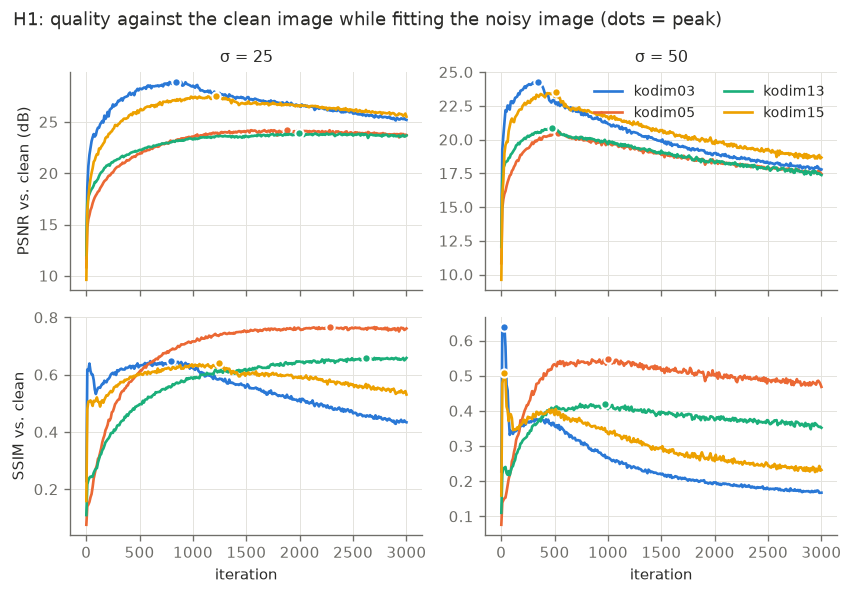

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), sharex=True)
for col, sigma in enumerate((25, 50)):
    for k, im in enumerate(IMAGES):
        g = h1[(h1.image == im) & (h1.sigma == sigma) & (h1.seed == 0)]
        for row, metric in enumerate(("psnr_clean", "ssim_clean")):
            ax = axes[row, col]
            ax.plot(g["iter"], g[metric], color=PALETTE[k], label=im)
            i = g[metric].idxmax()
            ax.plot(g.loc[i, "iter"], g.loc[i, metric], "o", ms=5, color=PALETTE[k], mec="white", mew=1.2)
    axes[0, col].set_title(f"σ = {sigma}")
axes[0, 0].set_ylabel("PSNR vs. clean (dB)")
axes[1, 0].set_ylabel("SSIM vs. clean")
for ax in axes[1]:
    ax.set_xlabel("iteration")
axes[0, 1].legend(loc="upper right", ncols=2)
fig.suptitle("H1: quality against the clean image while fitting the noisy image (dots = peak)", x=0.02, ha="left")
fig.tight_layout()
savefig(fig, "h1_curves")

**Teaser figure.** Clean, noisy, DIP output near the peak and at the end, for `kodim03`, σ = 25. Output snapshots exist only at iterations 100, 500, 1000, 2000 and 3000. We use the one closest to the PSNR peak.

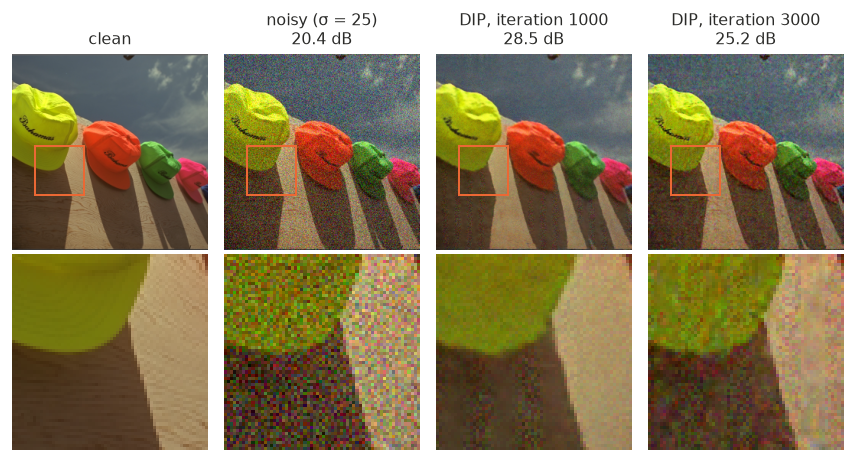

In [6]:
run = "unet_kodim03_noisy_s25_seed0"
g = h1[h1.run == run]
peak_iter = int(g.loc[g["psnr_clean"].idxmax(), "iter"])
snap_iters = np.array([100, 500, 1000, 2000, 3000])
near = int(snap_iters[np.abs(snap_iters - peak_iter).argmin()])

x = load_image(DATA_DIR / "kodim03.png")
y = add_gaussian_noise(x, 25, seed=0)
def psnr_at(it):
    return g.loc[(g["iter"] - it).abs().idxmin(), "psnr_clean"]
panels = [
    ("clean", to_numpy_image(x), None),
    ("noisy (σ = 25)", to_numpy_image(y), seed0[(seed0.image == "kodim03") & (seed0.sigma == 25)].noisy_psnr.item()),
    (f"DIP, iteration {near}", io.imread(RESULTS_DIR / "h1" / "img" / f"{run}_it{near}.png") / 255, psnr_at(near)),
    ("DIP, iteration 3000", io.imread(RESULTS_DIR / "h1" / "img" / f"{run}_it3000.png") / 255, psnr_at(3000)),
]
r0, c0, s = 120, 30, 64  # zoom window (row, col, size)
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.9), gridspec_kw={"height_ratios": [1, 1]})
for k, (title, img, p) in enumerate(panels):
    axes[0, k].imshow(img)
    axes[0, k].add_patch(plt.Rectangle((c0, r0), s, s, fill=False, ec="#eb6834", lw=1.2))
    axes[0, k].set_title(title if p is None else f"{title}\n{p:.1f} dB")
    axes[1, k].imshow(img[r0:r0 + s, c0:c0 + s], interpolation="nearest")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
fig.tight_layout()
savefig(fig, "teaser")

## Findings

- **H1 is confirmed.** Every run shows a clear PSNR peak followed by a decline.
- **The drop grows with noise:** on average about 1.6 dB at σ = 25 vs. 4.5 dB at σ = 50, and the peak comes much earlier at σ = 50.
- **Image content matters.** For the textured images `kodim05` and `kodim13`, the peak at σ = 25 comes late (~1900–2000 iterations) and the drop within 3000 iterations is small. Fine texture behaves like high-frequency content and is fitted late, together with the noise.
- **Seed variability is ~0.1 dB**, so differences of 0.5 dB or more are meaningful.
- **SSIM mostly agrees with PSNR,** with one caveat: SSIM shows a short spike after 20–40 iterations, when the output is still a very smooth image. On images with large smooth regions, SSIM briefly rewards this blur even though PSNR is low. The metrics are reported side by side for this reason.